In [37]:
from __future__ import annotations

import json
from pathlib import Path

import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np
from ase.io import read

ROOT = Path("/home/mahpe/Code/Agenticoptimizer")
RUN_ROOT = ROOT / "runs" / "convergence"

RUNS = {
    "MC": RUN_ROOT / "mc",
    #"GA": RUN_ROOT / "ga",
    "Agent (random)": RUN_ROOT / "agent_random",
    #"Agent (openai)": RUN_ROOT / "agent_openai",
    "Agent (cursor)": RUN_ROOT / "agent_cursor",
}

In [38]:

convergence_plot = {}

for key, item in RUNS.items():
    traj = read(item / "atom_swaps.xyz", index=":")
    convergence_plot[key] = {'energy':[],'steps':[]}
    for i, atoms in enumerate(traj):  
        convergence_plot[key]['energy'].append(atoms.get_potential_energy())
        convergence_plot[key]['steps'].append(i)




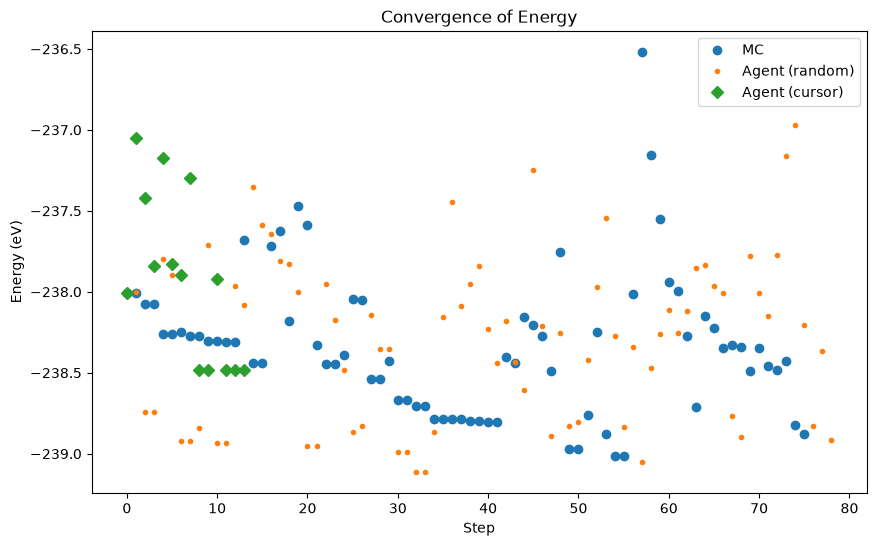

In [39]:
fig, ax = plt.subplots(figsize=(10, 6))

font_size = 12
fmt = {'MC': 'o', 'Agent (random)': '.', 'Agent (openai)': 's', 'Agent (cursor)': 'D'}

for label, data in convergence_plot.items():
    ax.plot(data['steps'], data['energy'], fmt[label], label=label,linewidth=2)

ax.set_xlabel('Step')
ax.set_ylabel('Energy (eV)')
ax.set_title('Convergence of Energy')
ax.legend()

In [ ]:
def load_from_summary_file(path: Path) -> tuple[np.ndarray, np.ndarray] | None:
    if not path.is_file():
        return None
    summary = json.loads(path.read_text(encoding="utf-8"))
    records = summary.get("steps")
    if not records:
        return None
    steps, energies = [], []
    for rec in records:
        step = rec.get("step")
        energy = rec.get("best_energy_eV", rec.get("energy"))
        if step is None or energy is None:
            continue
        steps.append(int(step))
        energies.append(float(energy))
    if not steps:
        return None
    order = np.argsort(steps)
    steps_arr = np.asarray(steps, dtype=int)[order]
    energy_arr = np.asarray(energies, dtype=float)[order]
    return steps_arr, np.minimum.accumulate(energy_arr)


def load_from_xyz(run_dir: Path) -> tuple[np.ndarray, np.ndarray] | None:
    """Fallback: build convergence from atom_swaps.xyz while summary.json is missing."""
    from ase.io import read

    traj = run_dir / "atom_swaps.xyz"
    if not traj.is_file():
        return None
    frames = read(traj, index=":")
    if not frames:
        return None

    steps = []
    energies = []
    for i, atoms in enumerate(frames):
        label = atoms.info.get("label", f"frame_{i}")
        energy = atoms.info.get("energy_eV")
        if energy is None and atoms.calc is not None:
            try:
                energy = atoms.get_potential_energy()
            except RuntimeError:
                energy = None
        if energy is None:
            continue
        step_num = i
        if label.startswith("step_"):
            try:
                step_num = int(label.split("_")[1])
            except ValueError:
                step_num = i
        steps.append(step_num)
        energies.append(float(energy))

    if not steps:
        return None
    order = np.argsort(steps)
    steps_arr = np.asarray(steps, dtype=int)[order]
    energy_arr = np.asarray(energies, dtype=float)[order]
    return steps_arr, np.minimum.accumulate(energy_arr)


def load_convergence(run_dir: Path) -> tuple[np.ndarray, np.ndarray] | None:
    """Return (steps, best_energy_so_far) from summary files or atom_swaps.xyz."""
    for name in ("summary.json", "summary_partial.json"):
        curve = load_from_summary_file(run_dir / name)
        if curve is not None:
            return curve
    return load_from_xyz(run_dir)


def run_status(run_dir: Path) -> str:
    if (run_dir / "summary.json").is_file():
        return "done"
    if (run_dir / "summary_partial.json").is_file() or (run_dir / "atom_swaps.xyz").is_file():
        return "running"
    if run_dir.is_dir():
        return "starting"
    log = RUN_ROOT / f"{run_dir.name}.log"
    if log.is_file():
        return "running (log only)"
    return "missing"

In [ ]:
curves: dict[str, tuple[np.ndarray, np.ndarray]] = {}

print("Run status:")
for label, run_dir in RUNS.items():
    status = run_status(run_dir)
    curve = load_convergence(run_dir)
    if curve is not None:
        curves[label] = curve
        n = len(curve[0])
        print(f"  {label:18s}  {status:16s}  {n} points  best={curve[1][-1]:.6f} eV")
    else:
        print(f"  {label:18s}  {status:16s}  (no summary yet)")

In [ ]:
fig, ax = plt.subplots(figsize=(10, 6))

for label, (steps, best_energy) in curves.items():
    ax.plot(steps, best_energy, linewidth=1.8, label=label)

ax.set_xlabel("Step / generation")
ax.set_ylabel("Best total energy (eV)")
ax.set_title("Convergence — AuCu disordered 2×2×2 supercell")
ax.legend()
ax.grid(True, alpha=0.3)
fig.tight_layout()
plt.show()

In [ ]:
# Per-step energy (not cumulative best) for MC and agents
fig, ax = plt.subplots(figsize=(10, 6))

for label, run_dir in RUNS.items():
    summary_path = run_dir / "summary.json"
    if not summary_path.is_file():
        continue
    summary = json.loads(summary_path.read_text(encoding="utf-8"))
    records = summary.get("steps", [])
    if not records or "energy" not in records[0] and "best_energy_eV" not in records[0]:
        continue

    steps = [int(r["step"]) for r in records if "step" in r]
    energies = [
        float(r.get("energy", r.get("best_energy_eV")))
        for r in records
        if "step" in r
    ]
    if label == "GA":
        continue  # GA steps already store best per generation
    ax.scatter(steps, energies, s=8, alpha=0.5, label=label)

ax.set_xlabel("Step")
ax.set_ylabel("Total energy at step (eV)")
ax.set_title("Per-step energies (MC / agents)")
ax.legend()
ax.grid(True, alpha=0.3)
fig.tight_layout()
plt.show()